# Checkpoint 2

Estimating the location and extent of slow conduction regions in the heart is a classic inverse problem in cardiac electrophysiology. In this checkpoint, you will use mathematical modeling and computational techniques to estimate the position and radius of slow conduction areas from activation times annotated on electrogram measurements (see Checkpoint 1).

A key tool for this task is the **eikonal equation**, a simplified model of cardiac electrophysiology that describes activation time as a function of spatial coordinates. The eikonal formulation provides a fast and efficient way to reconstruct activation patterns, making it well suited for PDE-constrained optimization, physics-informed neural networks, and the generation of in silico datasets for scientific machine learning.

Using one of these approaches, you will estimate the location and size of slow conduction regions—by minimizing the discrepancy between simulated and observed activation times.
You will also account for unknown tissue properties, including conduction velocity and anisotropy, which play a crucial role in wavefront propagation. The velocity of slow conduction areas is assumed to be common across all patients and therefore needs to be estimated only once.


In [1]:
# imports

import numpy as np
import matplotlib.pyplot as plt


# Physics-based model implementation

Implemenatation of the algorithm presented in :

Sermesant, Maxime, et al. "An anisotropic multi-front fast marching method for real-time simulation of cardiac electrophysiology." Functional Imaging and Modeling of the Heart: 4th International Conference, FIHM 2007, Salt Lake City, UT, USA, June 7-9, 2007. Proceedings 4. Springer Berlin Heidelberg, 2007.

In [2]:
import numpy as np
import heapq

def anisotropic_FMM_GPT(
    x0, y0, t0,
    X, Y,
    speed_input,
    sigma_11, sigma_12, sigma_22,
    N_edge=None
):
    """
    Fast-marching style solver with anisotropy and spatially varying speed.

    Parameters
    ----------
    x0, y0 : float
        Initial source location.
    t0 : float
        Initial activation time.
    X, Y : 2D ndarray
        Grid coordinates.
    speed_input : float, callable, or 2D ndarray
        Can be:
        - a scalar: constant speed everywhere
        - a function: speed_input(x, y)
        - a 2D array with same shape as X, Y
    sigma_11, sigma_12, sigma_22 : float
        Components of the inverse of conductivity tensor.
    N_edge : int or None
        Optional. If None, inferred from grid shape.

    Returns
    -------
    T_final : 2D ndarray
        Arrival time map.
    """

    nrows, ncols = X.shape
    if N_edge is None:
        N_edge = nrows - 1

    INF = 1e4
    P = np.linspace(0.0, 1.0, 11)

    # nearest grid node to source
    j0 = np.abs(X[0, :] - x0).argmin()
    i0 = np.abs(Y[:, 0] - y0).argmin()

    T = np.full((nrows, ncols), INF, dtype=float)
    T_final = np.full((nrows, ncols), INF, dtype=float)

    T[i0, j0] = t0
    T_final[i0, j0] = t0

    known = np.zeros((nrows, ncols), dtype=bool)

    # min-heap of (arrival_time, i, j)
    heap = [(t0, i0, j0)]

    def get_speed(i, j, x, y):
        if callable(speed_input):
            val = speed_input(x, y)
        elif np.isscalar(speed_input):
            val = speed_input
        else:
            val = speed_input[i, j]

        if val <= 0:
            raise ValueError(f"Speed must be positive. Got {val} at ({i}, {j}).")
        return val

    def metric_dist(xa, ya, xb, yb, speed_val):
        dx = xa - xb
        dy = ya - yb
        return np.sqrt(
            sigma_11 * dx * dx +
            2.0 * sigma_12 * dx * dy +
            sigma_22 * dy * dy
        ) / speed_val

    def update_fun(
        T_xi, T_x, T_y,
        X_xi, X_x, X_y,
        Y_xi, Y_x, Y_y,
        flag_known,
        i_xi, j_xi
    ):
        speed_val = get_speed(i_xi, j_xi, X_xi, Y_xi)

        if flag_known:
            dx = P * (X_xi - X_x) + (1.0 - P) * (X_xi - X_y)
            dy = P * (Y_xi - Y_x) + (1.0 - P) * (Y_xi - Y_y)

            triangle_vals = (
                P * T_x + (1.0 - P) * T_y
                + np.sqrt(
                    sigma_11 * dx * dx +
                    2.0 * sigma_12 * dx * dy +
                    sigma_22 * dy * dy
                ) / speed_val
            )
            cand = triangle_vals.min()
        else:
            cand = T_x + metric_dist(X_xi, Y_xi, X_x, Y_x, speed_val)

        return min(T_xi, cand)

    # side nodes used for triangle updates
    side_map = {
        (-1,  0): [(-1, +1), (-1, -1)],  # north
        (+1,  0): [(+1, +1), (+1, -1)],  # south
        ( 0, -1): [(+1, -1), (-1, -1)],  # west
        ( 0, +1): [(+1, +1), (-1, +1)],  # east
    }

    while heap:
        t_sel, i_sel, j_sel = heapq.heappop(heap)

        # ignore stale entries
        if known[i_sel, j_sel]:
            continue
        if t_sel > T_final[i_sel, j_sel]:
            continue

        known[i_sel, j_sel] = True

        # visit 4-neighbors
        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, +1)]:
            ni, nj = i_sel + di, j_sel + dj

            if not (0 <= ni < nrows and 0 <= nj < ncols):
                continue
            if known[ni, nj]:
                continue

            new_T = INF

            for sdi, sdj in side_map[(di, dj)]:
                si, sj = i_sel + sdi, j_sel + sdj

                if not (0 <= si < nrows and 0 <= sj < ncols):
                    continue

                new_T = update_fun(
                    T_xi=new_T,
                    T_x=T_final[i_sel, j_sel],
                    T_y=T_final[si, sj],
                    X_xi=X[ni, nj], X_x=X[i_sel, j_sel], X_y=X[si, sj],
                    Y_xi=Y[ni, nj], Y_x=Y[i_sel, j_sel], Y_y=Y[si, sj],
                    flag_known=known[si, sj],
                    i_xi=ni, j_xi=nj
                )

            if new_T < T_final[ni, nj]:
                T[ni, nj] = new_T
                T_final[ni, nj] = new_T
                heapq.heappush(heap, (new_T, ni, nj))

    return T_final

# Eikonal equation

Let us consider the Eikonal model: find T(x,y)

\begin{aligned}
  & 80 \sqrt{ \nabla T(x,y) D \nabla T(x,y)} = 1  \,, \quad (x,y) \in [-2,2] \times [-2,2]\,,\\
  & u(x,y) = t_0,t_1  \,, \qquad \qquad \qquad \qquad \qquad x=x_0,x_1,y=y_0,y_1 \,, \\
\end{aligned}

where 
\begin{aligned}
D = 1\ \vec{b} \otimes \vec{b} + \frac{1}{a_{ratio}}  \ \vec{a} \otimes \vec{a},
\end{aligned}
being $ \vec{b} $ the given fiber orientation and $ \vec{a} $ the given cross-fiber orientation (orthogonal to $ \vec{b}$).

The unknown parameters of the problem are: 
- conduction velocity (tissue property common to all the patients),
- anisotropy ratio $a_{ratio}$ (tissue property common to all the patients),
- the slow conduction positions $(x_{SC},y_{SC})$ and its radius $r_{SC}$.

In [3]:
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0,2.0,401), np.linspace(-2.0,2.0,401))

x0 = -1.5
y0 = -1

theta_fiber = 0
a_ratio = 5

theta0 = np.pi/2 - theta_fiber
a = np.array([np.cos(theta0), np.sin(theta0)]).T
b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
print(D)

D_inv = np.linalg.inv(D)
sigma_11 = D_inv[0][0]
sigma_12 = D_inv[0][1]
sigma_21 = D_inv[1][0]
sigma_22 = D_inv[1][1]

xc, yc = 0.5, 0.5
r = 0.5

speed_field = lambda x, y: 20.0 if (x - xc)**2 + (y - yc)**2 <= r**2 else 80.0

activation_time = anisotropic_FMM_GPT( x0 , y0 , 0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )




[[1.0000000e+00 1.2246468e-17]
 [1.2246468e-17 2.0000000e-01]]


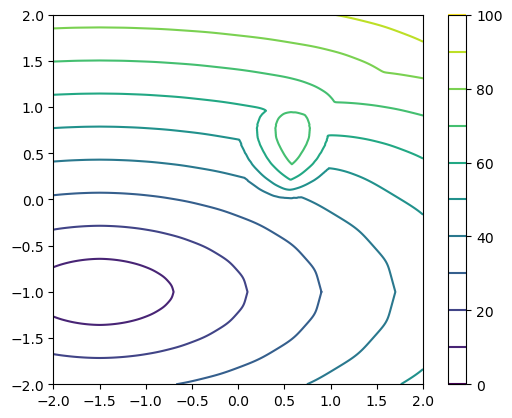

In [4]:

plt.contour(X_mesh, Y_mesh, activation_time*1000 , 10) 
plt.gca().set_aspect(1)
plt.colorbar()

In [5]:
N_samples = 1

np.random.seed(32)

measurements_dataset = []
groundtruth_dataset = []

for i_sample in range(N_samples):

    x0 = np.random.uniform(low=1.5,high=1.5)
    y0 = np.random.uniform(low=-1.5,high=1.5)
    x1 = np.random.uniform(low=1.5,high=1.5)
    y1 = np.random.uniform(low=-1.5,high=1.5)
    theta_fiber = 0.0
    a_ratio = np.random.uniform(low=1,high=9)

    theta0 = np.pi/2 - theta_fiber
    a = np.array([np.cos(theta0), np.sin(theta0)]).T
    b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

    D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
    print(D)

    D_inv = np.linalg.inv(D)
    sigma_11 = D_inv[0][0]
    sigma_12 = D_inv[0][1]
    sigma_21 = D_inv[1][0]
    sigma_22 = D_inv[1][1]

    # compute activation time
    activation_time = anisotropic_FMM_GPT( x0 , y0 , 0.0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )

    # rescaling in ms
    activation_time = activation_time*1e3

    # measurements location
    Spline_spacing = [0.5, 0.7, 1.3, 1.5]
    Angles_spacing =  [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5 ]
    
    index_extracted = []
    x_meas = []
    y_meas = []
    time_meas = []

    for i in range(4):
        #print(i)
        for j in range(5):
            #print(j)
            MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]) )**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]) )**2
            [i_sel, j_sel] = np.unravel_index(MeasMat.argmin(), MeasMat.shape) 
            index_extracted.append(i_sel)
            x_meas.append(X_mesh[i_sel,j_sel])
            y_meas.append(Y_mesh[i_sel,j_sel])
            time_meas.append(activation_time[i_sel,j_sel])

    measurements_dataset.append( [ x_meas, y_meas, time_meas ] )
    groundtruth_dataset.append([activation_time])

[[1.00000000e+00 8.88280440e-18]
 [8.88280440e-18 1.45067205e-01]]


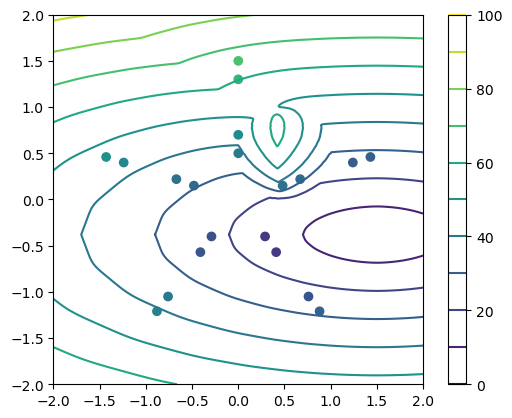

In [6]:
plt.figure(1)
plt.scatter( x_meas, y_meas, c=time_meas, vmin= 0, vmax=np.max(activation_time) )
plt.contour(X_mesh, Y_mesh, activation_time , 10)
plt.gca().set_aspect(1)
plt.colorbar()

# Checkpoint 2

Implement your algorithm to process the traces of the 20 unipolar electrogram signals and identify the center and radius of the slow conduction region.

The algorithm must return the following outputs:

1. **slow conduction center** 
2. **slow conduction radius**

Therefore output should be in the following form:
[x_SC,y_SC,r_SC] 

Provide your algorithm's implementation in this notebook usign the signature defined below.

In [7]:
# load data
signals = np.load('checkpoint2dataset.npy')

# select event to be display
ind_event = 0

signals_event = signals[ind_event,:,:]

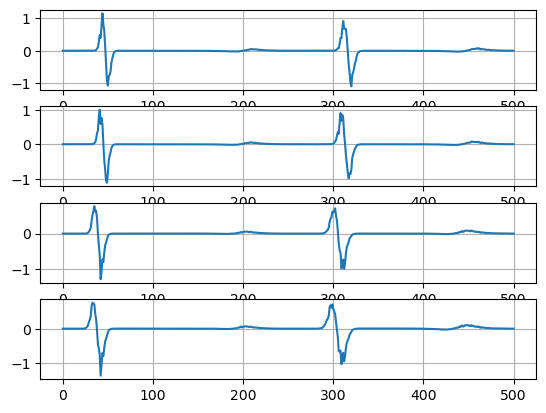

In [8]:
# select a spline (options: 0,1,2,3,4)
ind_spline = 0
# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

In [9]:
# known starting points (to test your algorithm)
# Note that a rescaling with respect to the center is needed
impulse_sites = np.load('checkpoint2FocalPoints.npy') -2.0
[x0,y0] = impulse_sites[0][0]
[x1,y1] = impulse_sites[0][1]

# t_0, t_1 can be extracted from the file: "checkpoint2starting.npy"

In [13]:
import numpy as np
from scipy.optimize import minimize
from scipy.signal import argrelextrema, savgol_filter
import warnings
warnings.filterwarnings("ignore")

# ==========================================
# 0. FUNZIONE ESTRAZIONE TEMPI (DA CP1)
# ==========================================
def GroupSolutionCP1(signals_event):
    sig_filtered = savgol_filter(signals_event, window_length=11, polyorder=3, axis=1)
    n_sensors = sig_filtered.shape[0]
    timings = []
    min_dist = 100 
    
    for i in range(n_sensors):
        ds = np.gradient(sig_filtered[i, :])
        min_indices = argrelextrema(ds, np.less)[0]
        
        selected = []
        if len(min_indices) > 0:
            depths = ds[min_indices]
            sorted_args = np.argsort(depths)
            candidates = min_indices[sorted_args]
            
            for idx in candidates:
                if len(selected) == 0:
                    selected.append(idx)
                elif len(selected) == 1:
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break
            selected.sort()

        row_time = [None, None]
        for j in range(min(len(selected), 2)):
            row_time[j] = int(selected[j])
        
        row_final = [t if t is not None else np.nan for t in row_time]
        timings.append(row_final)

    return timings

# ==========================================
# 1. SETUP SPAZIALE
# ==========================================
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0, 2.0, 401), np.linspace(-2.0, 2.0, 401))
X_mesh_vel, Y_mesh_vel = np.meshgrid(np.linspace(-2.0, 2.0, 201), np.linspace(-2.0, 2.0, 201))
X_mesh_100, Y_mesh_100 = np.meshgrid(np.linspace(-2.0, 2.0, 101), np.linspace(-2.0, 2.0, 101))
Spline_spacing = [0.5, 0.7, 1.3, 1.5]
Angles_spacing = [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5]

meas_indices = []
for i in range(4):
    for j in range(5):
        MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        i_sel, j_sel = np.unravel_index(MeasMat.argmin(), MeasMat.shape)
        meas_indices.append((i_sel, j_sel))

meas_indices_vel = []
for i in range(4):
    for j in range(5):
        MeasMat_vel = (X_mesh_vel - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh_vel - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        i_sel, j_sel = np.unravel_index(MeasMat_vel.argmin(), MeasMat_vel.shape)
        meas_indices_vel.append((i_sel, j_sel))

meas_indices_100 = []
for i in range(4):
    for j in range(5):
        MeasMat_100 = (X_mesh_100 - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh_100 - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        i_sel, j_sel = np.unravel_index(MeasMat_100.argmin(), MeasMat_100.shape)
        meas_indices_100.append((i_sel, j_sel))

# ==========================================
# 2. CARICAMENTO DATI UFFICIALI
# ==========================================
signals = np.load('checkpoint2dataset.npy') 
impulse_sites = np.load('checkpoint2FocalPoints.npy') - 2.0 
starting_times = np.load('checkpoint2starting.npy') 

# INSERISCI I DATI REALI forniti per l'anisotropia
a_ratios_training = np.load('checkpoint2anisotropy.npy') # DA SOSTITUIRE

reference_targets = [
    [-0.407, 0.299, 0.578],
    [0.81, 0.113, 0.394],
    [-0.816, -0.686, 0.274],
    [0.197, -0.242, 0.042],
    [0.647, -0.69, 0.244]
] #

# ==========================================
# 3. PRE-ESTRAZIONE TEMPI MISURATI (2 BATTITI)
# ==========================================
measured_times_beat1 = []
measured_times_beat2 = []

for idx_event in range(5):
    raw_timings = GroupSolutionCP1(signals[idx_event, :, :])
    
    # Estraiamo i tempi del primo e del secondo battito
    t_beat1 = np.array([t[0] for t in raw_timings], dtype=float)
    t_beat2 = np.array([t[1] for t in raw_timings], dtype=float)
    
    measured_times_beat1.append(t_beat1)
    measured_times_beat2.append(t_beat2)

# ==========================================
# 4. FUNZIONE OBIETTIVO CON VELOCITÀ SFUMATA (TANH)
# ==========================================
def objective_velocities(velocities):
    v_base, v_slow = velocities
    total_mse = 0.0
    
    # Parametro di ripidezza del bordo (k)
    # 50.0 rende il bordo netto ma matematicamente derivabile
    k = 50.0 
    
    for idx in range(5):
        xc, yc, r = reference_targets[idx]
        a_ratio = a_ratios_training[idx]**2
        
        # 1. Costruzione tensore di diffusione (Anisotropia)
        theta0 = 0 # fiber_theta assumed 0
        a = np.array([np.cos(theta0), np.sin(theta0)])
        b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)])
        D = ((1/a_ratio)*np.outer(a, a) + np.outer(b, b))
        D_inv = np.linalg.inv(D)
        sigma_11, sigma_12, sigma_22 = D_inv[0,0], D_inv[0,1], D_inv[1,1]
        
        # 2. CREAZIONE CAMPO VELOCITÀ SFUMATO (Sostituisce il lambda)
        # Calcoliamo la distanza di ogni punto della mesh dal centro dell'ischemia
        # dist = np.sqrt((X_mesh_vel - xc)**2 + (Y_mesh_vel - yc)**2)
        
        # Funzione peso basata su tanh: 0 all'interno, 1 all'esterno
        # weight = 0.5 * (1 + np.tanh(k * (dist - r)))
        
        # Matrice delle velocità (vettorializzata, molto più veloce del lambda)
        # speed_grid = v_slow + weight * (v_base - v_slow)

        speed_field = lambda x, y: v_slow + 0.5 * (1 + np.tanh(k * (np.hypot(x - xc, y - yc) - r))) * (v_base - v_slow)
        
        # NOTA: anisotropic_FMM_GPT deve ora accettare 'speed_grid' (matrice) 
        # invece di 'speed_field' (funzione). 
        # Se la tua FMM accetta solo funzioni, passagli: lambda x, y: speed_grid
        
        # --- SIMULAZIONE BATTITO 1 ---
        x0, y0 = impulse_sites[idx][0]
        t0 = starting_times[idx][0]/1000.0
        
        sim_beat1 = anisotropic_FMM_GPT(
            x0, y0, t0, X_mesh_vel, Y_mesh_vel, speed_field, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0
        
        sim_times1 = np.array([sim_beat1[i, j] for i, j in meas_indices_vel])
        meas_times1 = measured_times_beat1[idx]
        
        mask1 = ~np.isnan(meas_times1)
        if np.any(mask1):
            total_mse += np.mean((sim_times1[mask1] - meas_times1[mask1])**2)
            
        # --- SIMULAZIONE BATTITO 2 ---
        x1, y1 = impulse_sites[idx][1]
        t1 = starting_times[idx][1]/1000.0
        
        sim_beat2 = anisotropic_FMM_GPT(
            x1, y1, t1, X_mesh_vel, Y_mesh_vel, speed_field, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0
        
        sim_times2 = np.array([sim_beat2[i, j] for i, j in meas_indices_vel])
        meas_times2 = measured_times_beat2[idx]
        
        mask2 = ~np.isnan(meas_times2)
        if np.any(mask2):
            total_mse += np.mean((sim_times2[mask2] - meas_times2[mask2])**2)
        
    return total_mse

# ==========================================
# 5. AVVIO OTTIMIZZAZIONE
# ==========================================
initial_guess = [80.0, 20.0] 
bounds = [(40.0, 150.0), (5.0, 40.0)] 

print("Inizio calibrazione delle velocità (su 2 battiti per paziente)...")
result = minimize(objective_velocities, initial_guess, method='Nelder-Mead', bounds=bounds, options={'xatol': 1.0, 'fatol': 0.1})

if result.success:
    print(f"\n✅ Ottimizzazione convergente!")
    print(f"Velocità tessuto sano (v_base): {result.x[0]:.2f}")
    print(f"Velocità tessuto lento (v_slow): {result.x[1]:.2f}")
else:
    print("\n❌ L'ottimizzatore non ha trovato un minimo:", result.message)

Inizio calibrazione delle velocità (su 2 battiti per paziente)...

✅ Ottimizzazione convergente!
Velocità tessuto sano (v_base): 124.75
Velocità tessuto lento (v_slow): 19.69


### signature of the function ###

In [ ]:
# ==========================================
# 6. SALVATAGGIO DELLE VELOCITÀ STIMATE
# ==========================================
if result.success:
    EST_V_BASE = result.x[0]
    EST_V_SLOW = result.x[1]
else:
    # Valori di fallback in caso di fallimento della calibrazione
    EST_V_BASE = 80.0
    EST_V_SLOW = 20.0

def find_best_start(patient_cost_func):
    print("🚀 Scanning globale dello spazio (Pos, R, Aniso)...")
    best_mse = float('inf')
    best_params = [0.0, 0.0, 0.5, 3.0]
    
    # Aumentiamo a 150 punti per coprire adeguatamente le 4 dimensioni
    np.random.seed(42) 
    random_starts = np.random.uniform(
        low=[-1.5, -1.5, 0.2, 1.5], 
        high=[1.5, 1.5, 1.2, 5.0], 
        size=(150, 4)
    )
    
    for p in random_starts:
        mse = patient_cost_func(p)
        if mse < best_mse:
            best_mse = mse
            best_params = p
            
    print(f"📍 Punto di partenza ottimale: Pos=[{best_params[0]:.3f}, {best_params[1]:.3f}], R={best_params[2]:.2f}, Aniso={best_params[3]:.1f} (MSE: {best_mse:.2f})")
    return best_params

# ==========================================
# 7. FUNZIONE FINALE (FASE 2) - VERSIONE CORRETTA
# ==========================================
def GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1):
    global EST_V_BASE, EST_V_SLOW
    
    # --- 1. ESTRAZIONE TEMPI ---
    raw_timings = GroupSolutionCP1(signals_event)
    meas_beat1 = np.array([t[0] if len(t) > 0 else np.nan for t in raw_timings], dtype=float)
    meas_beat2 = np.array([t[1] if len(t) > 1 else np.nan for t in raw_timings], dtype=float)
    
    # --- 2. ALLINEAMENTO TEMPI (in secondi) ---
    t_0 = t_0 / 1000.0
    t_1 = t_1 / 1000.0    

    # --- 3. FUNZIONE DI OTTIMIZZAZIONE ---
    def patient_cost(params):
        xc, yc, r, a_ratio_square = params
        a_ratio=a_ratio_square**2
        total_mse = 0.0
        
        # Ripidezza per la transizione continua
        k = 50.0
                
        # COSTANTE CORRETTA: theta0 deve essere 0.0 per coerenza con la Sez. 4
        theta0 = 0.0 
        a = np.array([np.cos(theta0), np.sin(theta0)])
        b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)])
        D = ((1/a_ratio)*np.outer(a, a) + np.outer(b, b))
        D_inv = np.linalg.inv(D)
        sigma_11, sigma_12, sigma_22 = D_inv[0,0], D_inv[0,1], D_inv[1,1]
        
        # CAMPO VELOCITÀ CONTINUO (FONDAMENTALE PER NELDER-MEAD)
        # La distanza euclidea viene passata alla tanh per creare un gradiente liscio
        speed_field = lambda x, y: EST_V_SLOW + 0.5 * (1 + np.tanh(k * (np.hypot(x - xc, y - yc) - r))) * (EST_V_BASE - EST_V_SLOW)

        # Simulazione BATTITO 1
        sim_beat1 = anisotropic_FMM_GPT(
            x_0, y_0, t_0, X_mesh_vel, Y_mesh_vel, speed_field, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0 
        
        sim_times1 = np.array([sim_beat1[i, j] for i, j in meas_indices_vel])
        mask1 = ~np.isnan(meas_beat1)
        if np.any(mask1):
            total_mse += np.mean((sim_times1[mask1] - meas_beat1[mask1])**2)
            
        # Simulazione BATTITO 2
        sim_beat2 = anisotropic_FMM_GPT(
            x_1, y_1, t_1, X_mesh_vel, Y_mesh_vel, speed_field, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0 
        
        sim_times2 = np.array([sim_beat2[i, j] for i, j in meas_indices_vel])
        mask2 = ~np.isnan(meas_beat2)
        if np.any(mask2):
            total_mse += np.mean((sim_times2[mask2] - meas_beat2[mask2])**2)
            
        return total_mse

    # --- 8. ESECUZIONE ---
    initial_guess = find_best_start(patient_cost)
    
    # Manteniamo confini ragionevoli (il cuore virtuale è in [-2, 2])
    bounds = [(-2.0, 2.0), (-2.0, 2.0), (0.1, 1.5), (1.0, 8.0)]
    
    # Ottimizzazione locale a partire dal seed migliore
    res_patient = minimize(patient_cost, initial_guess, method='Nelder-Mead', bounds=bounds, options={
        'xatol': 0.001,
        'fatol': 0.01,
        'maxiter': 300,  # Aumentato per permettere la convergenza sul gradiente liscio
        'adaptive': True
    })
    
    return [res_patient.x[0], res_patient.x[1], res_patient.x[2]]

In [15]:
# ==========================================
# TEST RAPIDO SUL PRIMO PAZIENTE (SCENARIO 1)
# ==========================================

print("=== AVVIO TEST SINGOLO (Scenario 1) ===\n")

# Indice 0 corrisponde al primo scenario
idx = 0

# 1. Estrazione dati
signals_event = signals[idx, :, :]
x_0, y_0 = impulse_sites[idx][0]
x_1, y_1 = impulse_sites[idx][1]
t_0 = starting_times[idx][0]
t_1 = starting_times[idx][1]
true_x, true_y, true_r = reference_targets[idx]

# 2. Avvio predizione (vedrai apparire la barra di caricamento qua sotto)
print("Avvio simulazione. Elaborazione in corso...\n")
predicted_target = GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1)
pred_x, pred_y, pred_r = predicted_target

# 3. Calcolo e stampa degli errori
center_err = np.sqrt((pred_x - true_x)**2 + (pred_y - true_y)**2)
r_err = abs(pred_r - true_r)

print(f"\n✅ Test Completato!")
print(f"Target Reale  : Centro [{true_x:6.3f}, {true_y:6.3f}], Raggio: {true_r:5.3f}")
print(f"Target Stimato: Centro [{pred_x:6.3f}, {pred_y:6.3f}], Raggio: {pred_r:5.3f}")
print(f"Errore Centro : {center_err:.4f} cm")
print(f"Errore Raggio : {r_err:.4f} cm")

=== AVVIO TEST SINGOLO (Scenario 1) ===

Avvio simulazione. Elaborazione in corso...

🚀 Scanning globale dello spazio (Pos, R, Aniso)...
📍 Punto di partenza ottimale: Pos=[-0.304, 0.348], R=0.84, Aniso=1.7 (MSE: 804.72)

✅ Test Completato!
Target Reale  : Centro [-0.407,  0.299], Raggio: 0.578
Target Stimato: Centro [-0.506,  0.542], Raggio: 0.749
Errore Centro : 0.2627 cm
Errore Raggio : 0.1706 cm


In [16]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# GRAFICO 1: VISUALIZZAZIONE GEOMETRICA
# ==========================================
def plot_geometric_solution(true_target, pred_target, impulses, sensors_indices, X_mesh, Y_mesh):
    """
    Sovrappone le circonferenze geometriche della lesione reale e di quella stimata,
    mostrando la dislocazione spaziale dei sensori e dei punti di stimolo.
    """
    true_x, true_y, true_r = true_target
    pred_x, pred_y, pred_r = pred_target
    x0, y0, x1, y1 = impulses

    fig, ax = plt.subplots(figsize=(8, 8))

    # Disegna la lesione reale
    circle_true = plt.Circle((true_x, true_y), true_r, color='green', fill=False, linewidth=2.5, linestyle='--', label='Lesione Reale (Ground Truth)')
    ax.add_patch(circle_true)

    # Disegna la lesione stimata
    circle_pred = plt.Circle((pred_x, pred_y), pred_r, color='red', fill=False, linewidth=2.5, label='Lesione Stimata (Ottimizzatore)')
    ax.add_patch(circle_pred)

    # Estrae le coordinate spaziali dei sensori dalla mesh
    sens_x = [X_mesh[i, j] for i, j in sensors_indices]
    sens_y = [Y_mesh[i, j] for i, j in sensors_indices]
    ax.scatter(sens_x, sens_y, c='black', marker='x', s=40, label='Sensori di misurazione')

    # Posiziona i due punti di stimolo (impulsi)
    ax.scatter([x0, x1], [y0, y1], c='blue', marker='*', s=200, label='Punti di stimolo (t0, t1)')

    # Formattazione assi
    ax.set_xlim([-2.0, 2.0])
    ax.set_ylim([-2.0, 2.0])
    ax.set_aspect('equal')
    ax.set_title("Confronto Geometrico: Lesione Reale vs Stimata")
    ax.set_xlabel("X (cm)")
    ax.set_ylabel("Y (cm)")
    ax.grid(True, linestyle=':', alpha=0.7)
    
    # Posiziona la legenda fuori dal grafico per non coprire i dati
    ax.legend(loc='upper right', bbox_to_anchor=(1.5, 1))
    plt.show()

# ==========================================
# GRAFICO 2: MAPPA DI CALORE (CAMPO DI VELOCITÀ)
# ==========================================
def plot_velocity_heatmap(true_target, pred_target, impulses, sensors_indices, X_mesh, Y_mesh, v_base, v_slow):
    """
    Ricostruisce la matrice delle velocità (con transizione tanh) generata dall'ottimizzatore
    e la mappa come contour plot per visualizzare fisicamente l'ostacolo affrontato dall'onda.
    """
    pred_x, pred_y, pred_r = pred_target
    true_x, true_y, true_r = true_target
    x0, y0, x1, y1 = impulses

    # Ricrea il campo vettoriale continuo esattamente come fatto nel "patient_cost"
    k = 25.0
    dist = np.hypot(X_mesh - pred_x, Y_mesh - pred_y)
    speed_grid = v_slow + 0.5 * (1 + np.tanh(k * (dist - pred_r))) * (v_base - v_slow)

    fig, ax = plt.subplots(figsize=(9, 8))

    # Mappa di calore della velocità
    heatmap = ax.pcolormesh(X_mesh, Y_mesh, speed_grid, shading='auto', cmap='YlOrRd_r')
    cbar = fig.colorbar(heatmap, ax=ax)
    cbar.set_label('Velocità di conduzione (cm/s)')

    # Sovrappone i sensori
    sens_x = [X_mesh[i, j] for i, j in sensors_indices]
    sens_y = [Y_mesh[i, j] for i, j in sensors_indices]
    ax.scatter(sens_x, sens_y, c='black', marker='x', s=40, label='Sensori')

    # Sovrappone gli stimoli
    ax.scatter([x0, x1], [y0, y1], c='blue', marker='*', s=200, edgecolors='white', label='Stimoli')

    # Disegna il perimetro della lesione reale in ciano per verificare visivamente l'errore sulla heatmap
    circle_true = plt.Circle((true_x, true_y), true_r, color='cyan', fill=False, linewidth=2, linestyle='--', label='Perimetro Reale')
    ax.add_patch(circle_true)

    # Formattazione assi
    ax.set_xlim([-2.0, 2.0])
    ax.set_ylim([-2.0, 2.0])
    ax.set_aspect('equal')
    ax.set_title("Mappa di Calore del Campo di Velocità Stimato")
    ax.set_xlabel("X (cm)")
    ax.set_ylabel("Y (cm)")
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1))
    
    plt.show()

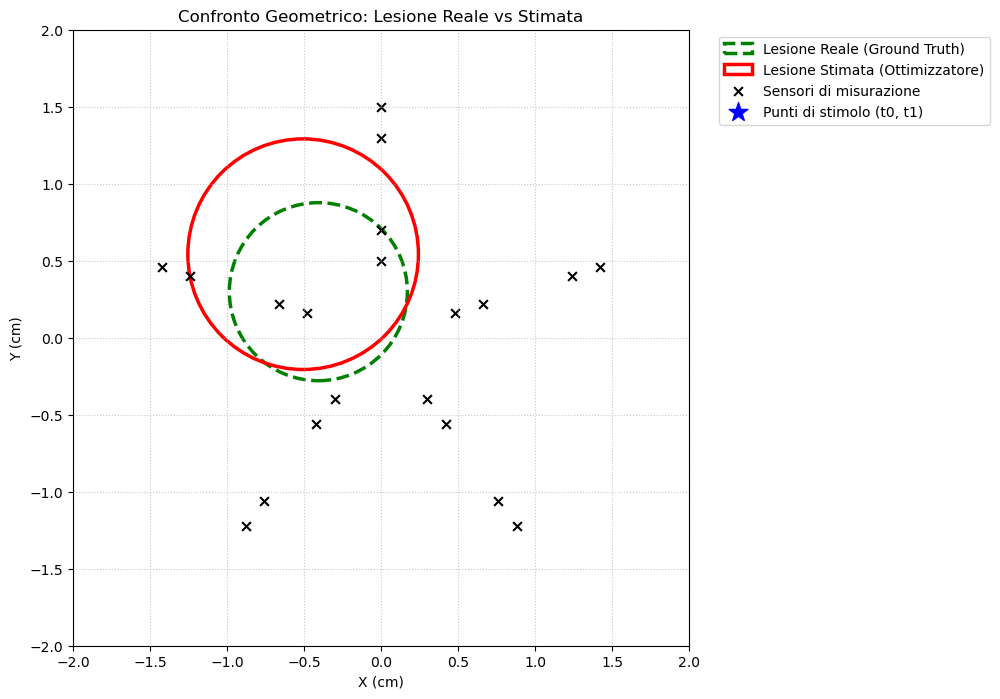

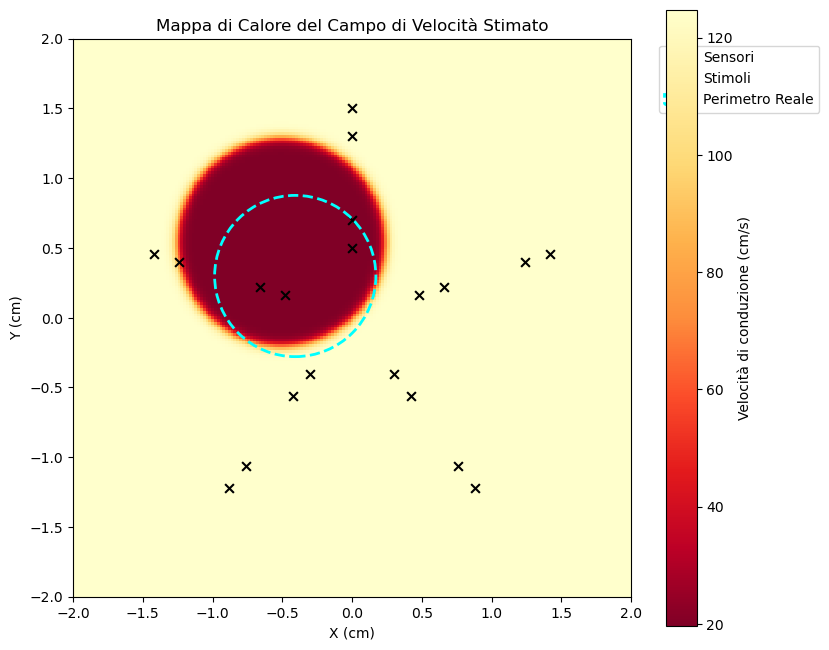

In [17]:
# Impacchetta le variabili per passarle alle funzioni di plot
target_reale_pack = [true_x, true_y, true_r]
target_stimato_pack = [pred_x, pred_y, pred_r]
impulsi_pack = [x_0, y_0, x_1, y_1]

# Richiama il Grafico Geometrico
plot_geometric_solution(
    true_target=target_reale_pack, 
    pred_target=target_stimato_pack, 
    impulses=impulsi_pack, 
    sensors_indices=meas_indices_vel, 
    X_mesh=X_mesh_vel, 
    Y_mesh=Y_mesh_vel
)

# Richiama la Mappa di Calore (assicurati che EST_V_BASE e EST_V_SLOW siano disponibili nel namespace globale)
plot_velocity_heatmap(
    true_target=target_reale_pack,
    pred_target=target_stimato_pack, 
    impulses=impulsi_pack, 
    sensors_indices=meas_indices_vel, 
    X_mesh=X_mesh_vel, 
    Y_mesh=Y_mesh_vel, 
    v_base=EST_V_BASE, 
    v_slow=EST_V_SLOW
)